# Study the 10 features one by one

This notebook will eventually study each selected feature through EDA, preprocessing, and standard scaling.

## Step 1 — Load the data into a pandas DataFrame

This first version only imports and joins the required data. It does not perform EDA, missing-value treatment, feature engineering, or scaling.

In [7]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_columns", 20)

### Locate the project files

This allows the notebook to run from either the project folder or the `notebooks` folder.

In [8]:
possible_roots = [Path.cwd(), Path.cwd().parent]
project_dir = next(
    (
        path
        for path in possible_roots
        if (path / "data" / "parquet_files" / "train" / "train_base.parquet").exists()
    ),
    None,
)

if project_dir is None:
    raise FileNotFoundError(
        "Run this notebook from the project folder or the notebooks folder."
    )

train_dir = project_dir / "data" / "parquet_files" / "train"

print("Project folder:", project_dir)
print("Training-data folder:", train_dir)

Project folder: d:\Home Credit - Credit Risk Model Stability
Training-data folder: d:\Home Credit - Credit Risk Model Stability\data\parquet_files\train


### Select the ten features

`case_id` will be used to join `static_0` to the base table. `WEEK_NUM` and `target` are retained for later time splitting and model evaluation.

In [9]:
selected_features = [
    "credamount_770A",
    "annuity_780A",
    "maininc_215A",
    "applications30d_658L",
    "numactivecreds_622L",
    "totaldebt_9A",
    "avgdbddpdlast24m_3658932P",
    "avgdpdtolclosure24_3658938P",
    "clientscnt12m_3712952L",
    "price_1097A",
]

selected_features

['credamount_770A',
 'annuity_780A',
 'maininc_215A',
 'applications30d_658L',
 'numactivecreds_622L',
 'totaldebt_9A',
 'avgdbddpdlast24m_3658932P',
 'avgdpdtolclosure24_3658938P',
 'clientscnt12m_3712952L',
 'price_1097A']

### Read the base table

The base table supplies the application identifier, time variable, and target.

In [10]:
base_df = pd.read_parquet(
    train_dir / "train_base.parquet",
    columns=["case_id", "WEEK_NUM", "target"],
)

print("base_df:", base_df.shape)

base_df: (1526659, 3)


### Read and combine both `static_0` partitions

The two Parquet files contain different rows of the same logical table. We read only `case_id` and the ten selected columns.

In [11]:
static_0_part_0_df = pd.read_parquet(
    train_dir / "train_static_0_0.parquet",
    columns=["case_id", *selected_features],
)

static_0_part_1_df = pd.read_parquet(
    train_dir / "train_static_0_1.parquet",
    columns=["case_id", *selected_features],
)

static_10_df = pd.concat(
    [static_0_part_0_df, static_0_part_1_df],
    ignore_index=True,
)

print("static_0_part_0_df:", static_0_part_0_df.shape)
print("static_0_part_1_df:", static_0_part_1_df.shape)
print("static_10_df combined:", static_10_df.shape)

static_0_part_0_df: (1003757, 11)
static_0_part_1_df: (522902, 11)
static_10_df combined: (1526659, 11)


### Join and assign the final pandas DataFrame

The final variable is named `df`. It contains one row per application, three base columns, and the ten selected features.

In [12]:
assert base_df["case_id"].is_unique
assert static_10_df["case_id"].is_unique

df = base_df.merge(
    static_10_df,
    on="case_id",
    how="left",
    validate="one_to_one",
)

assert len(df) == len(base_df)

print("Object type:", type(df))
print(f"df contains {df.shape[0]:,} rows and {df.shape[1]} columns")

df.head()

Object type: <class 'pandas.core.frame.DataFrame'>
df contains 1,526,659 rows and 13 columns


,case_id,WEEK_NUM,target,credamount_770A,annuity_780A,maininc_215A,applications30d_658L,numactivecreds_622L,totaldebt_9A,avgdbddpdlast24m_3658932P,avgdpdtolclosure24_3658938P,clientscnt12m_3712952L,price_1097A
0,0,0,0,30000.0,1917.6,NaN,0.0,0.0,0.0,NaN,NaN,0.0,NaN
1,1,0,0,19999.8,3134.0,NaN,0.0,0.0,0.0,NaN,NaN,0.0,NaN
2,2,0,0,78000.0,4937.0,NaN,0.0,0.0,0.0,NaN,NaN,0.0,NaN
3,3,0,0,40000.0,4643.6,NaN,1.0,0.0,0.0,NaN,NaN,0.0,NaN
4,4,0,1,44000.0,3390.2,NaN,1.0,0.0,0.0,NaN,NaN,0.0,NaN


## Step 1 complete

The data is now available in the pandas DataFrame named `df`. No EDA or preprocessing has been performed yet.

## Step 2 — Create chronological development splits

Before studying or preprocessing any feature, divide the labeled applications by `WEEK_NUM`:

| DataFrame | Weeks | Purpose |
|---|---:|---|
| `train_df` | 0–51 | Learn EDA-based rules, preprocessing values, and model parameters |
| `validation_df` | 52–71 | Check drift and compare development choices |
| `holdout_test_df` | 72–91 | Final one-time evaluation after the complete process is frozen |

This is a time-aware split. It is different from the separate unlabeled files under `data/parquet_files/test`.

In [13]:
train_mask = df["WEEK_NUM"].between(0, 51)
validation_mask = df["WEEK_NUM"].between(52, 71)
holdout_test_mask = df["WEEK_NUM"].between(72, 91)

# Every application must belong to exactly one period.
period_membership_count = (
    train_mask.astype("int8")
    + validation_mask.astype("int8")
    + holdout_test_mask.astype("int8")
)
assert period_membership_count.eq(1).all()

train_df = df.loc[train_mask].copy()
validation_df = df.loc[validation_mask].copy()
holdout_test_df = df.loc[holdout_test_mask].copy()

assert len(train_df) + len(validation_df) + len(holdout_test_df) == len(df)
assert train_df["case_id"].is_unique
assert validation_df["case_id"].is_unique
assert holdout_test_df["case_id"].is_unique
assert train_df["WEEK_NUM"].max() < validation_df["WEEK_NUM"].min()
assert validation_df["WEEK_NUM"].max() < holdout_test_df["WEEK_NUM"].min()

split_summary = pd.DataFrame({
    "dataframe": ["train_df", "validation_df", "holdout_test_df"],
    "week_range": ["0–51", "52–71", "72–91"],
    "applications": [len(train_df), len(validation_df), len(holdout_test_df)],
    "role": [
        "Learn preprocessing and model parameters",
        "Compare development choices and drift",
        "Locked final evaluation",
    ],
})

display(
    split_summary.style.format({
        "applications": "{:,.0f}",
    })
)

print("Chronological split checks passed.")

,dataframe,week_range,applications,role
0,train_df,0–51,"1,065,921",Learn preprocessing and model parameters
1,validation_df,52–71,"248,535",Compare development choices and drift
2,holdout_test_df,72–91,"212,203",Locked final evaluation


Chronological split checks passed.


### Rules for the remaining feature study

- Perform detailed EDA and learn cleaning rules from `train_df`.
- Apply those fixed rules to `validation_df` and compare stability.
- Do not inspect target relationships, distributions, missingness, or model performance in `holdout_test_df` during development.
- Fit imputers and scalers using `train_df` only.

The full `df` remains available as the joined source DataFrame. The three split DataFrames are explicit copies, which makes their roles clear but temporarily uses additional memory.

## Step 3 — Study `credamount_770A`: meaning and missing values

According to the supplied feature dictionary, `credamount_770A` is the **loan amount or credit-card limit** recorded for the application.

- `credamount` refers to the credit amount.
- The suffix `A` identifies an amount-type feature in this dataset.
- `770` is an internal feature identifier; it does not represent 770 currency units or a business calculation.

At this stage, we check only whether the feature is missing. We use training weeks 0–51 and development-validation weeks 52–71. Weeks 72–91 remain locked.

In [14]:
feature_name = "credamount_770A"

feature_definitions_df = pd.read_csv(
    project_dir / "data" / "feature_definitions.csv"
)

feature_definition = feature_definitions_df.loc[
    feature_definitions_df["Variable"].eq(feature_name),
    ["Variable", "Description"],
]

if feature_definition.empty:
    raise KeyError(f"No definition found for {feature_name}")

feature_definition

,Variable,Description
101,credamount_770A,Loan amount or credit card limit.


### Count missing values

`isna()` returns `True` when a value is missing. Summing those Boolean values gives the number of missing rows. The percentage is calculated relative to the number of applications in each development period.

In [15]:
development_frames = {
    "Training weeks 0–51": train_df,
    "Validation weeks 52–71": validation_df,
}

missing_rows = []
for period_name, period_df in development_frames.items():
    period_values = period_df[feature_name]
    missing_count = int(period_values.isna().sum())
    total_rows = len(period_values)
    missing_rows.append({
        "period": period_name,
        "applications": total_rows,
        "non_missing_count": total_rows - missing_count,
        "missing_count": missing_count,
        "missing_percent": 100 * missing_count / total_rows,
    })

combined_applications = sum(row["applications"] for row in missing_rows)
combined_missing = sum(row["missing_count"] for row in missing_rows)
missing_rows.append({
    "period": "Combined development weeks 0–71",
    "applications": combined_applications,
    "non_missing_count": combined_applications - combined_missing,
    "missing_count": combined_missing,
    "missing_percent": 100 * combined_missing / combined_applications,
})

credamount_missing_summary = pd.DataFrame(missing_rows)

display(
    credamount_missing_summary.style.format({
        "applications": "{:,.0f}",
        "non_missing_count": "{:,.0f}",
        "missing_count": "{:,.0f}",
        "missing_percent": "{:.4f}%",
    })
)

development_missing_count = combined_missing

print(f"Missing values in development data: {development_missing_count:,}")
print(
    "Conclusion:",
    "No imputation is required for credamount_770A in the current development data."
    if development_missing_count == 0
    else "This feature requires a missing-value treatment learned from training data.",
)

,period,applications,non_missing_count,missing_count,missing_percent
0,Training weeks 0–51,"1,065,921","1,065,921",0,0.0000%
1,Validation weeks 52–71,"248,535","248,535",0,0.0000%
2,Combined development weeks 0–71,"1,314,456","1,314,456",0,0.0000%


Missing values in development data: 0
Conclusion: No imputation is required for credamount_770A in the current development data.


### Missing-value conclusion

The executed output shows whether `credamount_770A` requires imputation in the current development data. A future production pipeline should still define safe behavior for an unexpected missing value, even when none appears during development.

No distribution analysis, outlier treatment, imputation, or scaling has been performed in this step.

## Step 4 — `credamount_770A` distribution and relationship with target

This section uses `train_df` only. It answers:

1. What range of credit amounts occurs in the training period?
2. Is the distribution concentrated or strongly right-skewed?
3. How does the observed default rate change across credit-amount groups?

The charts do not change the feature. One histogram is visually restricted to the training 1st–99th percentile range so the central distribution is readable; the model data remains unchanged.

In [16]:
credit_amount_train = train_df[feature_name]

credit_amount_quantiles = credit_amount_train.quantile(
    [0.00, 0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 1.00]
)

credit_amount_summary = pd.DataFrame({
    "statistic": [
        "Applications",
        "Minimum",
        "1st percentile",
        "5th percentile",
        "25th percentile",
        "Median",
        "75th percentile",
        "95th percentile",
        "99th percentile",
        "Maximum",
        "Mean",
        "Standard deviation",
    ],
    "value": [
        credit_amount_train.count(),
        credit_amount_quantiles.loc[0.00],
        credit_amount_quantiles.loc[0.01],
        credit_amount_quantiles.loc[0.05],
        credit_amount_quantiles.loc[0.25],
        credit_amount_quantiles.loc[0.50],
        credit_amount_quantiles.loc[0.75],
        credit_amount_quantiles.loc[0.95],
        credit_amount_quantiles.loc[0.99],
        credit_amount_quantiles.loc[1.00],
        credit_amount_train.mean(),
        credit_amount_train.std(),
    ],
})

display(credit_amount_summary.style.format({"value": "{:,.2f}"}))

,statistic,value
0,Applications,"1,065,921.00"
1,Minimum,"2,000.00"
2,1st percentile,"6,400.00"
3,5th percentile,"10,000.00"
4,25th percentile,"19,600.00"
5,Median,"33,998.00"
6,75th percentile,"60,144.20"
7,95th percentile,"140,000.00"
8,99th percentile,"200,000.00"
9,Maximum,"470,592.00"


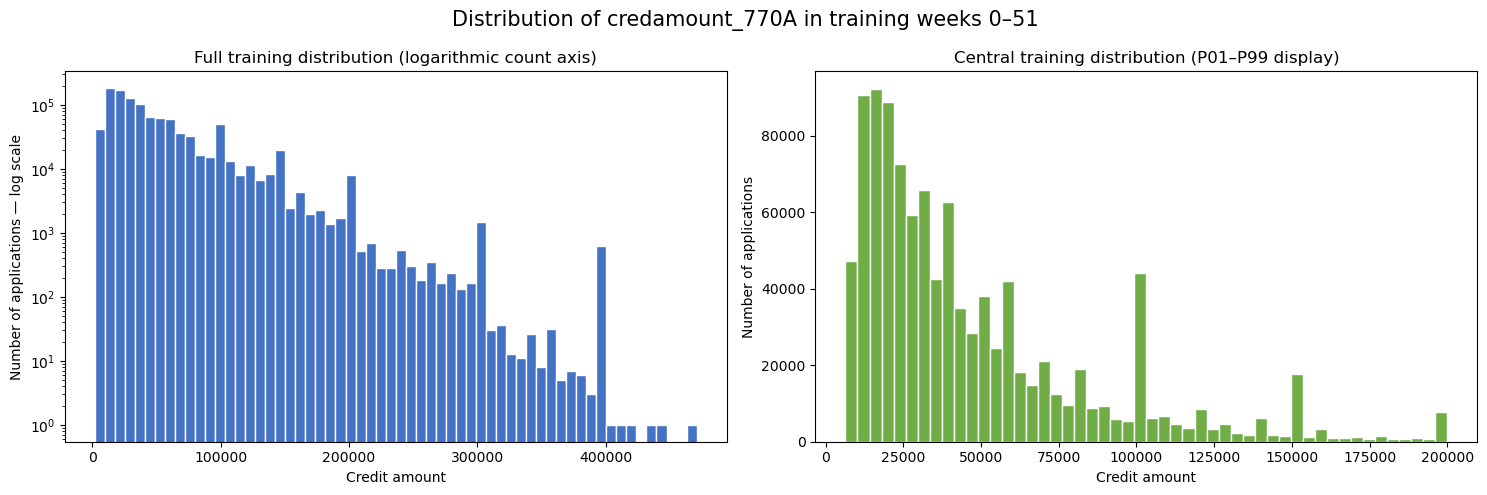

Displayed central range: 6,400.00 to 200,000.00
No rows or values were changed by the display restriction.


In [17]:
p01 = credit_amount_quantiles.loc[0.01]
p99 = credit_amount_quantiles.loc[0.99]
central_credit_amounts = credit_amount_train.between(p01, p99)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].hist(
    credit_amount_train,
    bins=60,
    color="#4472C4",
    edgecolor="white",
)
axes[0].set_yscale("log")
axes[0].set_title("Full training distribution (logarithmic count axis)")
axes[0].set_xlabel("Credit amount")
axes[0].set_ylabel("Number of applications — log scale")

axes[1].hist(
    credit_amount_train.loc[central_credit_amounts],
    bins=50,
    color="#70AD47",
    edgecolor="white",
)
axes[1].set_title("Central training distribution (P01–P99 display)")
axes[1].set_xlabel("Credit amount")
axes[1].set_ylabel("Number of applications")

fig.suptitle("Distribution of credamount_770A in training weeks 0–51", fontsize=15)
fig.tight_layout()
plt.show()

print(f"Displayed central range: {p01:,.2f} to {p99:,.2f}")
print("No rows or values were changed by the display restriction.")

### Relationship with `target`

To avoid the large non-default class hiding the default class, divide training applications into ten credit-amount groups using training quantiles. Decile 1 contains the lowest amounts and decile 10 the highest amounts.

For each group, calculate the observed proportion of `target = 1`. This is a descriptive relationship, not proof that changing the loan amount causes default.

,credit_amount_decile,applications,defaults,observed_default_rate,minimum_credit_amount,median_credit_amount,maximum_credit_amount
0,1,"106,969","3,510",3.281%,"2,000.00","10,000.00","12,400.00"
1,2,"106,646","3,525",3.305%,"12,400.40","14,732.00","16,998.00"
2,3,"106,169","3,161",2.977%,"16,998.20","19,630.60","21,178.00"
3,4,"106,775","2,986",2.797%,"21,178.60","24,000.00","26,998.00"
4,5,"107,309","3,199",2.981%,"26,998.20","30,000.00","33,998.00"
5,6,"106,672","2,997",2.810%,"33,998.20","39,196.00","42,000.00"
6,7,"105,605","2,693",2.550%,"42,000.40","48,400.00","54,398.00"
7,8,"106,752","3,171",2.970%,"54,398.40","60,172.00","71,978.00"
8,9,"112,619","3,591",3.189%,"71,979.00","90,000.00","100,000.00"
9,10,"100,405","4,096",4.079%,"100,000.20","140,000.00","470,592.00"


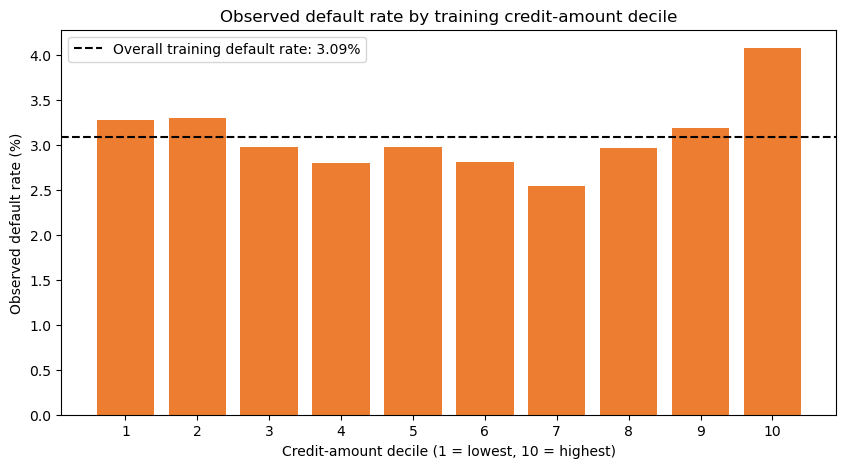

In [18]:
credit_target_train = train_df[[feature_name, "target"]].copy()
credit_target_train["credit_amount_decile"] = (
    pd.qcut(
        credit_target_train[feature_name],
        q=10,
        labels=False,
        duplicates="drop",
    )
    + 1
)

credit_amount_target_summary = (
    credit_target_train
    .groupby("credit_amount_decile", observed=True)
    .agg(
        applications=("target", "size"),
        defaults=("target", "sum"),
        observed_default_rate=("target", "mean"),
        minimum_credit_amount=(feature_name, "min"),
        median_credit_amount=(feature_name, "median"),
        maximum_credit_amount=(feature_name, "max"),
    )
    .reset_index()
)

overall_training_default_rate = train_df["target"].mean()

display(
    credit_amount_target_summary.style.format({
        "credit_amount_decile": "{:.0f}",
        "applications": "{:,.0f}",
        "defaults": "{:,.0f}",
        "observed_default_rate": "{:.3%}",
        "minimum_credit_amount": "{:,.2f}",
        "median_credit_amount": "{:,.2f}",
        "maximum_credit_amount": "{:,.2f}",
    })
)

fig, axis = plt.subplots(figsize=(10, 5))
axis.bar(
    credit_amount_target_summary["credit_amount_decile"],
    100 * credit_amount_target_summary["observed_default_rate"],
    color="#ED7D31",
)
axis.axhline(
    100 * overall_training_default_rate,
    color="black",
    linestyle="--",
    label=f"Overall training default rate: {overall_training_default_rate:.2%}",
)
axis.set_title("Observed default rate by training credit-amount decile")
axis.set_xlabel("Credit-amount decile (1 = lowest, 10 = highest)")
axis.set_ylabel("Observed default rate (%)")
axis.set_xticks(credit_amount_target_summary["credit_amount_decile"])
axis.legend()
plt.show()

### How to read these graphs

- The histogram shows how frequently different amounts occur.
- A long right tail means a small number of applications have much larger amounts than most applications.
- The decile chart shows association with the target while retaining all training rows.
- A non-monotonic chart would suggest that one straight-line logistic-regression effect may be too simple.
- No value has been removed, capped, logged, imputed, or standardized yet.

Validation stability should be checked using bin boundaries learned from training before making a preprocessing decision.